In [1]:
import rasterio
import numpy as np
from scipy import ndimage
from pathlib import Path
import pandas as pd
import gc

import openpyxl
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter

import time 
from collections import Counter

import re
import math

import winsound

import rasterio
from rasterio.windows import Window
from rasterio.errors import WindowError
from rasterio.windows import Window, from_bounds
from rasterio.features import geometry_mask
from rasterio.plot import show
from rasterio.mask import mask as rio_mask

import geopandas as gpd
import os
from matplotlib.ticker import FuncFormatter  # needed later for format_k
from shapely.geometry import shape

from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

In [2]:
folder = Path(r"C:\Users\") # change to your folder
tiff_files = sorted(folder.glob("Reclass_img_*_v0806.tif"))

TARGET_CLASS = 3   # Forest Formation
EDGE_WIDTH = 18    # pixels (1 pixel = 30 m edge depth) -> 500 m edge, max reach

# Core components smaller than this (in pixels) are stripped out of "core" and
# folded into Islet instead — a 1-pixel core is noise/artifact, not a real
# interior core. Set to 1 to only drop single-pixel cores, or raise it if you
# want a slightly larger minimum "real core" size.
MIN_CORE_PIXELS = 2

# Perforation components larger than this are reclassified as Edge instead —
# a "perforation" this big reads more like a large internal clearing than a
# true small interior gap. Tune to your definition of "too big."
MAX_PERFORATION_AREA_HA = 500.0
PIXEL_AREA_HA = 0.079956  # 30m x 30m pixel, matches area_ha calc below (aproximate)
MAX_PERFORATION_PIXELS = int(MAX_PERFORATION_AREA_HA / PIXEL_AREA_HA)

# Islet size classes, by connected-component area:
#   small islet  : area_ha < SMALL_ISLET_MAX_HA
#   medium islet : SMALL_ISLET_MAX_HA <= area_ha <= BIG_ISLET_MIN_HA
#   big islet    : area_ha > BIG_ISLET_MIN_HA
SMALL_ISLET_MAX_HA = 100.0
BIG_ISLET_MIN_HA = 500.0

struct = ndimage.generate_binary_structure(2, 1)  # 4-connectivity, standard for MSPA

mspa_classes = {
    1: "Core", 2: "Small Islet", 3: "Perforation", 4: "Edge", #5: "Connector",
    6: "Medium Islet", 7: "Big Islet",
}

def smallest_uint(n_labels):
    """Pick the smallest dtype that can hold label ids up to n_labels."""
    if n_labels < 2**8:
        return np.uint8
    elif n_labels < 2**16:
        return np.uint16
    return np.uint32

results = []

for tif_path in tiff_files:
    with rasterio.open(tif_path) as src:
        data = src.read(1)
        nodata = src.nodata
        profile = src.profile.copy()

    fg = (data == TARGET_CLASS)
    nodata_mask = (data == nodata) if nodata is not None else None
    del data
    gc.collect()

    out = np.zeros(fg.shape, dtype=np.uint8)

    # ---- Core ----
    core = ndimage.binary_erosion(fg, structure=struct, iterations=EDGE_WIDTH, border_value=0)

    # ---- Strip out tiny core components (e.g. single pixels) BEFORE they can
    # ever be treated as "real" core — regions left with zero core pixels
    # after this will correctly fall into Islet via the existing logic below.
    labeled_core, num_core = ndimage.label(core, structure=struct)
    labeled_core = labeled_core.astype(smallest_uint(num_core), copy=False)
    if num_core > 0:
        core_comp_sizes = ndimage.sum(core, labeled_core, index=np.arange(1, num_core + 1))
        tiny_core_labels = np.where(core_comp_sizes < MIN_CORE_PIXELS)[0] + 1
        if len(tiny_core_labels) > 0:
            tiny_core_mask = np.isin(labeled_core, tiny_core_labels)
            core &= ~tiny_core_mask
            del tiny_core_mask
        del core_comp_sizes, tiny_core_labels
    del labeled_core
    gc.collect()

    out[core] = 1
    del core
    gc.collect()

    # ---- Islet, split into Small / Medium / Big by connected-component area ----
    # Foreground regions with zero surviving core pixels are Islet — this now
    # also correctly catches regions whose only "core" was a tiny sliver
    # removed above, not just regions that never eroded down to any core.
    labeled_fg, num_fg = ndimage.label(fg, structure=struct)
    labeled_fg = labeled_fg.astype(smallest_uint(num_fg), copy=False)
    core_labels = set(np.unique(labeled_fg[out == 1])) - {0}
    all_labels = set(np.unique(labeled_fg)) - {0}
    islet_labels = all_labels - core_labels

    if islet_labels:
        islet_label_arr = np.array(sorted(islet_labels))
        comp_pixel_counts = ndimage.sum(fg, labeled_fg, index=islet_label_arr)
        comp_area_ha = comp_pixel_counts * PIXEL_AREA_HA

        small_labels = islet_label_arr[comp_area_ha < SMALL_ISLET_MAX_HA]
        medium_labels = islet_label_arr[
            (comp_area_ha >= SMALL_ISLET_MAX_HA) & (comp_area_ha <= BIG_ISLET_MIN_HA)
        ]
        big_labels = islet_label_arr[comp_area_ha > BIG_ISLET_MIN_HA]

        if len(small_labels) > 0:
            out[np.isin(labeled_fg, small_labels) & fg] = 2
        if len(medium_labels) > 0:
            out[np.isin(labeled_fg, medium_labels) & fg] = 6
        if len(big_labels) > 0:
            out[np.isin(labeled_fg, big_labels) & fg] = 7

        del comp_pixel_counts, comp_area_ha, small_labels, medium_labels, big_labels, islet_label_arr

    del labeled_fg
    gc.collect()

    # Remaining unclassified foreground
    rest = fg & (out == 0)

    # ---- Background labeling: holes (enclosed) vs exterior ----
    bg = ~fg
    del fg
    gc.collect()

    labeled_bg, num_bg = ndimage.label(bg, structure=struct)
    labeled_bg = labeled_bg.astype(smallest_uint(num_bg), copy=False)
    border_labels = (set(np.unique(labeled_bg[0, :])) | set(np.unique(labeled_bg[-1, :])) |
                      set(np.unique(labeled_bg[:, 0])) | set(np.unique(labeled_bg[:, -1]))) - {0}

    hole_mask = bg & ~np.isin(labeled_bg, list(border_labels))
    ext_mask = bg & np.isin(labeled_bg, list(border_labels))
    del labeled_bg, bg
    gc.collect()

    # ---- Distance to each background type, one at a time to limit peak memory ----
    CAP = EDGE_WIDTH + 1

    dist_to_hole = ndimage.distance_transform_cdt(~hole_mask, metric="taxicab")
    del hole_mask
    np.clip(dist_to_hole, 0, CAP, out=dist_to_hole)
    dist_to_hole = dist_to_hole.astype(np.uint8, copy=False)
    gc.collect()

    dist_to_ext = ndimage.distance_transform_cdt(~ext_mask, metric="taxicab")
    del ext_mask
    np.clip(dist_to_ext, 0, CAP, out=dist_to_ext)
    dist_to_ext = dist_to_ext.astype(np.uint8, copy=False)
    gc.collect()

    # ---- Perforation = rest pixels whose NEAREST background is an enclosed hole ----
    perforation = rest & (dist_to_hole <= EDGE_WIDTH) & (dist_to_hole <= dist_to_ext)
    del dist_to_hole, dist_to_ext
    gc.collect()

    # ---- Size filter: oversized perforation components get demoted to rest (-> Edge) ----
    labeled_perf, num_perf = ndimage.label(perforation, structure=struct)
    labeled_perf = labeled_perf.astype(smallest_uint(num_perf), copy=False)
    if num_perf > 0:
        comp_sizes = ndimage.sum(perforation, labeled_perf, index=np.arange(1, num_perf + 1))
        oversized_labels = np.where(comp_sizes > MAX_PERFORATION_PIXELS)[0] + 1
        if len(oversized_labels) > 0:
            oversized_mask = np.isin(labeled_perf, oversized_labels)
            perforation &= ~oversized_mask
            del oversized_mask
        del comp_sizes, oversized_labels
    del labeled_perf
    gc.collect()

    out[perforation] = 3
    del perforation
    gc.collect()

    # Edge = everything else left in rest, including demoted oversized perforations
    edge = rest & (out == 0)
    out[edge] = 4
    del edge, rest
    gc.collect()

    if nodata_mask is not None:
        out[nodata_mask] = 255
        del nodata_mask
        gc.collect()

    out_path = folder / f"mspa_500mt_v500perforation_vIslets_{tif_path.stem}.tif"
    profile.update(dtype=rasterio.uint8, count=1, nodata=255, compress="lzw")
    with rasterio.open(out_path, "w", **profile) as dst:
        dst.write(out, 1)

    year = int(tif_path.stem.split("_")[2])
    values, counts = np.unique(out, return_counts=True)
    for v, c in zip(values, counts):
        if v == 255:
            continue
        results.append({
            "file": tif_path.name, "year": year,
            "class_name": mspa_classes.get(int(v), "Background" if v == 0 else f"Unknown_{v}"),
            "count": int(c), "area_ha": int(c) * 0.079956, "area_mha": int(c) * 0.079956 / 1_000_000, # 0.079956 es en la proyección que estamos usando (EPSG:102033)
        })

    print(f"Processed {tif_path.name}")
    del out
    gc.collect()

mspa_table = pd.DataFrame(results)
#mspa_table.to_csv(folder / "mspa_results.csv", index=False)
print(mspa_table.head(20))

Processed Reclass_img_1985_v0806.tif
Processed Reclass_img_1986_v0806.tif
Processed Reclass_img_1987_v0806.tif
Processed Reclass_img_1988_v0806.tif
Processed Reclass_img_1989_v0806.tif
Processed Reclass_img_1990_v0806.tif
Processed Reclass_img_1991_v0806.tif
Processed Reclass_img_1992_v0806.tif
Processed Reclass_img_1993_v0806.tif
Processed Reclass_img_1994_v0806.tif
Processed Reclass_img_1995_v0806.tif
Processed Reclass_img_1996_v0806.tif
Processed Reclass_img_1997_v0806.tif
Processed Reclass_img_1998_v0806.tif
Processed Reclass_img_1999_v0806.tif
Processed Reclass_img_2000_v0806.tif
Processed Reclass_img_2001_v0806.tif
Processed Reclass_img_2002_v0806.tif
Processed Reclass_img_2003_v0806.tif
Processed Reclass_img_2004_v0806.tif
Processed Reclass_img_2005_v0806.tif
Processed Reclass_img_2006_v0806.tif
Processed Reclass_img_2007_v0806.tif
Processed Reclass_img_2008_v0806.tif
Processed Reclass_img_2009_v0806.tif
Processed Reclass_img_2010_v0806.tif
Processed Reclass_img_2011_v0806.tif
P

In [13]:
# Folder containing the TIFF files
folder = Path(r"C:\Users\") # change to your folder

# Folder containing the AOI shapefiles to run the histogram over
aoi_folder = folder / "AOI"

# Find all matching TIFF files
tiff_files = sorted(folder.glob("mspa_500mt_v500perforation_vIslets_Reclass_img_*_v0806.tif"))
print(f"Found {len(tiff_files)} raster(s)")

Found 40 raster(s)


In [14]:
# Find all AOI shapefiles
shapefile_paths = sorted(aoi_folder.glob("*.shp"))
print(f"Found {len(shapefile_paths)} shapefile(s) in {aoi_folder}")

Found 5 shapefile(s) in C:\Users\ahuvi\Downloads\Paper_3\MapBiomas\AOI


In [17]:
# folder, tiff_files, shapefile_paths assumed already defined earlier in the notebook

# --- Manual renaming: map each shapefile's filename (without .shp) to the
# label you want used in its output table / filename. Any shapefile not
# listed here falls back to its own filename stem. Edit this dict to give
# each AOI a clean name. ---
SHAPEFILE_NAME_OVERRIDES = {
    # "raw_shapefile_stem": "Friendly Name",
    "AltoParana_adm_bound_50km_50perc_v3857": "APAF_studyarea",
    "alto_parana_3857": "APAF_ecoregion",
    "APAF_Argentina_4326": "Argentina",
    "APAF_Brazil_4326": "Brazil",
    "APAF_Paraguay_4326": "Paraguay",
}

for shp_path in shapefile_paths:

    shp_stem = shp_path.stem
    shp_label = SHAPEFILE_NAME_OVERRIDES.get(shp_stem, shp_stem)

    print(f"\n=== AOI: {shp_label} ({shp_path.name}) ===")

    aoi = gpd.read_file(shp_path)

    all_histograms = []

    # Cache the reprojected AOI geometries per raster CRS, so we only
    # reproject once even though the same CRS repeats across every year.
    reproj_cache = {}

    for tif_path in tiff_files:

        with rasterio.open(tif_path) as src:

            nodata = src.nodata
            crs_key = src.crs.to_string()

            if crs_key not in reproj_cache:
                aoi_reproj = aoi.to_crs(src.crs)
                geometries = [
                    geom for geom in aoi_reproj.geometry
                    if geom is not None and not geom.is_empty
                ]
                reproj_cache[crs_key] = geometries
            else:
                geometries = reproj_cache[crs_key]

            if not geometries:
                print(f"  Skipping {tif_path.name}: no valid geometries in {shp_label}")
                continue

            # Single crop+mask call: GDAL rasterizes the AOI polygon once and
            # reads only the intersecting window, instead of looping over
            # every raster block and re-rasterizing the polygon each time.
            try:
                clipped, clipped_transform = rio_mask(
                    src, geometries, crop=True, filled=True,
                    nodata=nodata if nodata is not None else 0
                )
            except ValueError:
                print(f"  Skipping {tif_path.name}: {shp_label} does not overlap raster")
                continue

            data = clipped[0]

            # Merge class 39 into class 19
           # data[data == 39] = 19

            valid = np.ones(data.shape, dtype=bool)
            if nodata is not None:
                valid &= (data != nodata)

            values, counts = np.unique(data[valid], return_counts=True)
            counts_dict = dict(zip(values.tolist(), counts.tolist()))

            del clipped, data, valid
            gc.collect()

        # Create histogram DataFrame
        df = pd.DataFrame({
            "file": tif_path.name,
            "shapefile": shp_label,
            "value": list(counts_dict.keys()),
            "count": list(counts_dict.values())
        })

        df = df.sort_values("value").reset_index(drop=True)

        all_histograms.append(df)

        print(f"  Processed {tif_path.name}: {len(df)} unique values")

    # Skip shapefile if no data was collected
    if not all_histograms:
        print(f"  No data collected for {shp_label}, skipping output")
        continue

    # Combine histograms
    histogram_table = pd.concat(all_histograms, ignore_index=True)

    # Pivot to wide format
    histogram_wide = (
        histogram_table
        .pivot(index="value", columns="file", values="count")
        .fillna(0)
    )

    # Save CSV files
    safe_label = shp_label.replace(" ", "_")

    histogram_table.to_csv(folder / f"histograms_mspa_long_{safe_label}.csv", index=False)
    histogram_wide.to_csv(folder / f"histograms_mspa_wide_{safe_label}.csv")

    print(f"  Saved: histograms_mspa_long_{safe_label}.csv / histograms_mspa_wide_{safe_label}.csv")
    print(histogram_table.head())

print("\nDone.")


=== AOI: APAF_ecoregion (alto_parana_3857.shp) ===
  Processed mspa_500mt_v500perforation_vIslets_Reclass_img_1985_v0806.tif: 7 unique values
  Processed mspa_500mt_v500perforation_vIslets_Reclass_img_1986_v0806.tif: 7 unique values
  Processed mspa_500mt_v500perforation_vIslets_Reclass_img_1987_v0806.tif: 7 unique values
  Processed mspa_500mt_v500perforation_vIslets_Reclass_img_1988_v0806.tif: 7 unique values
  Processed mspa_500mt_v500perforation_vIslets_Reclass_img_1989_v0806.tif: 7 unique values
  Processed mspa_500mt_v500perforation_vIslets_Reclass_img_1990_v0806.tif: 7 unique values
  Processed mspa_500mt_v500perforation_vIslets_Reclass_img_1991_v0806.tif: 7 unique values
  Processed mspa_500mt_v500perforation_vIslets_Reclass_img_1992_v0806.tif: 7 unique values
  Processed mspa_500mt_v500perforation_vIslets_Reclass_img_1993_v0806.tif: 7 unique values
  Processed mspa_500mt_v500perforation_vIslets_Reclass_img_1994_v0806.tif: 7 unique values
  Processed mspa_500mt_v500perforation

In [18]:
mspa_classes = {
    1: "Core", 2: "Small Islet", 3: "Perforation", 4: "Edge", 0: "No Forest", 6: "Medium Islet", 7: "Big Islet",
}

In [19]:
folder = Path(r"C:\Users\") # change to your folder

PIXEL_AREA_HA = 0.079956

# Find all per-shapefile long-format histogram CSVs produced earlier
histogram_files = sorted(folder.glob("histograms_mspa_long_*.csv"))
print(f"Found {len(histogram_files)} histogram file(s)")

all_processed = []

for hist_path in histogram_files:
    label = hist_path.stem.replace("histograms_mspa_long_", "")
    print(f"\n=== {hist_path.name} ===")

    histogram_table = pd.read_csv(hist_path)

    unique_values = histogram_table["value"].unique()
    print(sorted(unique_values))

    # Class name (fallback to "Unknown_<code>" if not in mapbiomas_classes)
    histogram_table["value_name"] = histogram_table["value"].map(mspa_classes).fillna(
        "Unknown_" + histogram_table["value"].astype(str)
    )
    print(histogram_table.head())

    # Area in hectares
    histogram_table["area_ha"] = histogram_table["count"] * PIXEL_AREA_HA
    print(histogram_table.head())

    # Wide table of area_ha, one row per value, one column per file (raster/year)
    histogram_wide_ha = histogram_table.pivot(index="value", columns="file", values="area_ha").fillna(0)

    # Area in million hectares
    histogram_table["area_mha"] = histogram_table["area_ha"] / 1_000_000
    print(histogram_table.head())

    # Percentage of each file's (this shapefile's, this year's raster) total area
    histogram_table["percentage"] = (
        histogram_table.groupby("file")["area_mha"]
        .transform(lambda x: (x / x.sum()) * 100)
    )
    print(histogram_table.head())

    # Save this shapefile's processed long table
    out_long = hist_path.with_name(f"histograms_mspa_long_{label}_with_area_pct.csv")
    histogram_table.to_csv(out_long, index=False)

    # Save this shapefile's wide area_ha table too
    out_wide = folder / f"histograms_mspa_wide_ha_{label}.csv"
    histogram_wide_ha.to_csv(out_wide)

    print(f"Saved: {out_long.name}, {out_wide.name}")

    all_processed.append(histogram_table)

Found 16 histogram file(s)

=== histograms_mspa_long_APAF_ecoregion.csv ===
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(6), np.int64(7)]
                                                file       shapefile  value  \
0  mspa_500mt_v500perforation_vIslets_Reclass_img...  APAF_ecoregion      0   
1  mspa_500mt_v500perforation_vIslets_Reclass_img...  APAF_ecoregion      1   
2  mspa_500mt_v500perforation_vIslets_Reclass_img...  APAF_ecoregion      2   
3  mspa_500mt_v500perforation_vIslets_Reclass_img...  APAF_ecoregion      3   
4  mspa_500mt_v500perforation_vIslets_Reclass_img...  APAF_ecoregion      4   

       count   value_name  
0  344543601    No Forest  
1   37600627         Core  
2   26705805  Small Islet  
3    6670431  Perforation  
4   51914588         Edge  
                                                file       shapefile  value  \
0  mspa_500mt_v500perforation_vIslets_Reclass_img...  APAF_ecoregion      0   
1  mspa_500mt_v500perforation_v

# Vectorize and compute number and areas of each Core and Islet


In [ ]:
folder = Path(r"C:\Users\") # change to your folder
countries_folder = Path(r"C:\Users\AOI") # change to your folder
shapefiles_out_folder = folder / "mspa_shapefiles"
shapefiles_out_folder.mkdir(exist_ok=True)

# MSPA class codes to extract, with their display names (Connector excluded)
CLASS_NAMES = {
    1: "Core",
    2: "Small Islet",
    3: "Perforation",
    4: "Edge",
    # 5: "Connector",
    6: "Medium Islet",
    7: "Big Islet",
}
TARGET_VALUES = list(CLASS_NAMES.keys())

# --- Manual renaming: map each country shapefile's filename (without .shp)
# to the label you want used in its output table / filename. Any shapefile
# not listed here falls back to its own filename stem. Edit this dict to
# give each country a clean name. ---

COUNTRY_NAME_OVERRIDES = {
    # "raw_shapefile_stem": "Friendly Name",
    "AltoParana_adm_bound_50km_50perc_v3857": "APAF_studyarea",
    "alto_parana_3857": "APAF_ecoregion",
    "APAF_Argentina_4326": "Argentina",
    "APAF_Brazil_4326": "Brazil",
    "APAF_Paraguay_4326": "Paraguay",
}

# Find all yearly mspa rasters
tif_files = sorted(folder.glob("mspa_500mt_v500perforation_vIslets_Reclass_img_*_v0806.tif")) 
print(f"Found {len(tif_files)} mspa raster(s)")

# Find all country shapefiles
country_shp_files = sorted(countries_folder.glob("*.shp"))
print(f"Found {len(country_shp_files)} country shapefile(s)")

summary_records = []

for tif_path in tif_files:
    # Extract year from filename, e.g.
    # mspa_500mt_v500perforation_vIslets_Reclass_img_2020_v0806.tif -> 2020
    m = re.search(r"Reclass_img_(\d{4})_v0806\.tif", tif_path.name)
    year = int(m.group(1)) if m else None

    for shp_path in country_shp_files:
        country_stem = shp_path.stem  # e.g. "APAF_Brazil_4326"
        country_name = COUNTRY_NAME_OVERRIDES.get(country_stem, country_stem)

        aoi = gpd.read_file(shp_path)

        with rasterio.open(tif_path) as src:
            aoi_reproj = aoi.to_crs(src.crs)
            geometries = [geom for geom in aoi_reproj.geometry if geom is not None]

            try:
                clipped_data, clipped_transform = rio_mask(
                    src, geometries, crop=True, filled=True, nodata=src.nodata
                )
            except ValueError:
                print(f"Skipping {tif_path.name} / {country_name}: no overlap")
                continue

            data = clipped_data[0]
            crs = src.crs

        # Keep only pixels belonging to the classes we care about
        pixel_mask = np.isin(data, TARGET_VALUES)

        empty_record = {"year": year, "country": country_name}
        empty_record.update({
            f"n_polygons_{name.replace(' ', '_')}": 0 for name in CLASS_NAMES.values()
        })

        if not pixel_mask.any():
            print(f"{tif_path.name} / {country_name}: no pixels in target classes")
            summary_records.append(empty_record)
            continue

        shapes_gen = rio_shapes(
            data, mask=pixel_mask, transform=clipped_transform, connectivity=8
        )

        records = []
        for geom, value in shapes_gen:
            value = int(value)
            records.append({
                "value": value,
                "class_name": CLASS_NAMES.get(value, f"Unknown_{value}"),
                "geometry": shape(geom),
            })

        gdf = gpd.GeoDataFrame(records, crs=crs)

        group_counts = gdf["value"].value_counts()

        record = {"year": year, "country": country_name}
        log_parts = []
        for value, name in CLASS_NAMES.items():
            n = int(group_counts.get(value, 0))
            record[f"n_polygons_{name.replace(' ', '_')}"] = n
            log_parts.append(f"{name}={n}")

        print(f"{tif_path.name} / {country_name}: " + ", ".join(log_parts))
        summary_records.append(record)

        # Save shapefile for this year/country
        safe_country = country_name.replace(" ", "_")
        out_shp = shapefiles_out_folder / f"mspa_500mt_groups_{safe_country}_{year}.shp"
        gdf.to_file(out_shp)

        del data, clipped_data, gdf, records
        gc.collect()

# Build and save summary table
summary_df = pd.DataFrame(summary_records).sort_values(["country", "year"]).reset_index(drop=True)
summary_csv = folder / "mspa_polygon_counts_by_year_AOI.csv"
summary_df.to_csv(summary_csv, index=False)

print(f"\nSummary table saved to: {summary_csv}")
print(summary_df.head(20))
# Simple beep: frequency (Hz), duration (ms)
winsound.Beep(1000, 500)

In [ ]:
folder = Path(r"C:\Users\")
countries_folder = Path(r"C:\Users\AOI")
shapefiles_out_folder = folder / "mspa_shapefiles"
shapefiles_out_folder.mkdir(exist_ok=True)
 
# MSPA class codes to extract, with their display names (Connector excluded)
CLASS_NAMES = {
    1: "Core",
    2: "Small Islet",
    3: "Perforation",
    4: "Edge",
    # 5: "Connector",
    6: "Medium Islet",
    7: "Big Islet",
}
TARGET_VALUES = list(CLASS_NAMES.keys())
 
# --- Manual renaming: map each country shapefile's filename (without .shp)
# to the label you want used in its output table / filename. Any shapefile
# not listed here falls back to its own filename stem. Edit this dict to
# give each country a clean name. ---
COUNTRY_NAME_OVERRIDES = {
    # "raw_shapefile_stem": "Friendly Name",
    "AltoParana_adm_bound_50km_50perc_v3857": "APAF_studyarea",
    "alto_parana_3857": "APAF_ecoregion",
    "APAF_Argentina_4326": "Argentina",
    "APAF_Brazil_4326": "Brazil",
    "APAF_Paraguay_4326": "Paraguay",
}
 
# Find all yearly mspa rasters
tif_files = sorted(folder.glob("mspa_500mt_v500perforation_vIslets_Reclass_img_*_v0806.tif"))
print(f"Found {len(tif_files)} mspa raster(s)")
 
# Find all country shapefiles
country_shp_files = sorted(countries_folder.glob("*.shp"))
print(f"Found {len(country_shp_files)} country shapefile(s)")
 
summary_records = []
area_stats_records = []  # per (year, country, class_name) area statistics
 
for tif_path in tif_files:
    # Extract year from filename, e.g.
    # mspa_500mt_v500perforation_vIslets_Reclass_img_2020_v0806.tif -> 2020
    m = re.search(r"Reclass_img_(\d{4})_v0806\.tif", tif_path.name)
    year = int(m.group(1)) if m else None
 
    for shp_path in country_shp_files:
        country_stem = shp_path.stem  # e.g. "APAF_Brazil_4326"
        country_name = COUNTRY_NAME_OVERRIDES.get(country_stem, country_stem)
 
        aoi = gpd.read_file(shp_path)
 
        with rasterio.open(tif_path) as src:
            aoi_reproj = aoi.to_crs(src.crs)
            geometries = [geom for geom in aoi_reproj.geometry if geom is not None]
 
            try:
                clipped_data, clipped_transform = rio_mask(
                    src, geometries, crop=True, filled=True, nodata=src.nodata
                )
            except ValueError:
                print(f"Skipping {tif_path.name} / {country_name}: no overlap")
                continue
 
            data = clipped_data[0]
            crs = src.crs
 
        # Keep only pixels belonging to the classes we care about
        pixel_mask = np.isin(data, TARGET_VALUES)
 
        empty_record = {"year": year, "country": country_name}
        empty_record.update({
            f"n_polygons_{name.replace(' ', '_')}": 0 for name in CLASS_NAMES.values()
        })
 
        if not pixel_mask.any():
            print(f"{tif_path.name} / {country_name}: no pixels in target classes")
            summary_records.append(empty_record)
            continue
 
        shapes_gen = rio_shapes(
            data, mask=pixel_mask, transform=clipped_transform, connectivity=8
        )
 
        records = []
        for geom, value in shapes_gen:
            value = int(value)
            records.append({
                "value": value,
                "class_name": CLASS_NAMES.get(value, f"Unknown_{value}"),
                "geometry": shape(geom),
            })
 
        gdf = gpd.GeoDataFrame(records, crs=crs)
 
        # Reproject output polygons to an equal-area CRS before saving
        gdf = gdf.to_crs("ESRI:102033")
 
        # Per-polygon area in hectares (ESRI:102033 is an equal-area CRS,
        # so .area on it gives accurate area in m^2)
        gdf["area_ha"] = gdf.geometry.area / 10_000
 
        group_counts = gdf["value"].value_counts()
 
        record = {"year": year, "country": country_name}
        log_parts = []
        for value, name in CLASS_NAMES.items():
            n = int(group_counts.get(value, 0))
            record[f"n_polygons_{name.replace(' ', '_')}"] = n
            log_parts.append(f"{name}={n}")
 
        print(f"{tif_path.name} / {country_name}: " + ", ".join(log_parts))
        summary_records.append(record)
 
        # --- Per-class area statistics (hectares) for this year/country ---
        area_stats = (
            gdf.groupby("class_name")["area_ha"]
            .agg(
                n_polygons="count",
                total_area_ha="sum",
                mean_area_ha="mean",
                median_area_ha="median",
                min_area_ha="min",
                max_area_ha="max",
                std_area_ha="std",
            )
            .reindex(list(CLASS_NAMES.values()))  # keep all classes, even with 0 polygons here
            .fillna(0)
            .reset_index()
        )
        area_stats.insert(0, "year", year)
        area_stats.insert(1, "country", country_name)
        area_stats_records.append(area_stats)
 
        # Save shapefile for this year/country
        safe_country = country_name.replace(" ", "_")
        out_shp = shapefiles_out_folder / f"mspa_500mt_groups_{safe_country}_{year}.shp"
        gdf.to_file(out_shp)
 
        del data, clipped_data, gdf, records
        gc.collect()
 
# Build and save summary table (polygon counts)
summary_df = pd.DataFrame(summary_records).sort_values(["country", "year"]).reset_index(drop=True)
summary_csv = folder / "mspa_polygon_counts_by_year_AOI.csv"
summary_df.to_csv(summary_csv, index=False)
 
print(f"\nSummary table saved to: {summary_csv}")
print(summary_df.head(20))
 
# Build and save area statistics table (per year, country, class)
if area_stats_records:
    area_stats_df = (
        pd.concat(area_stats_records, ignore_index=True)
        .sort_values(["country", "year", "class_name"])
        .reset_index(drop=True)
    )
    area_stats_csv = folder / "mspa_polygon_area_stats_by_year_AOI.csv"
    area_stats_df.to_csv(area_stats_csv, index=False)
 
    print(f"\nArea statistics table saved to: {area_stats_csv}")
    print(area_stats_df.head(20))
else:
    print("\nNo area statistics collected.")

# Plots

# Study Area

In [10]:
# open all excel:
folder = Path(r"C:\Users\") # change to your folder

fragment_stats = pd.read_csv(folder / "mspa_polygon_area_stats_by_year_AOI.csv")
mspa_studyarea = pd.read_csv(folder / "histograms_mspa_long_APAF_studyarea_with_area_pct.csv")

Y ranges used (top -> bottom): [(1037546, 1522282), (0, 29854)]


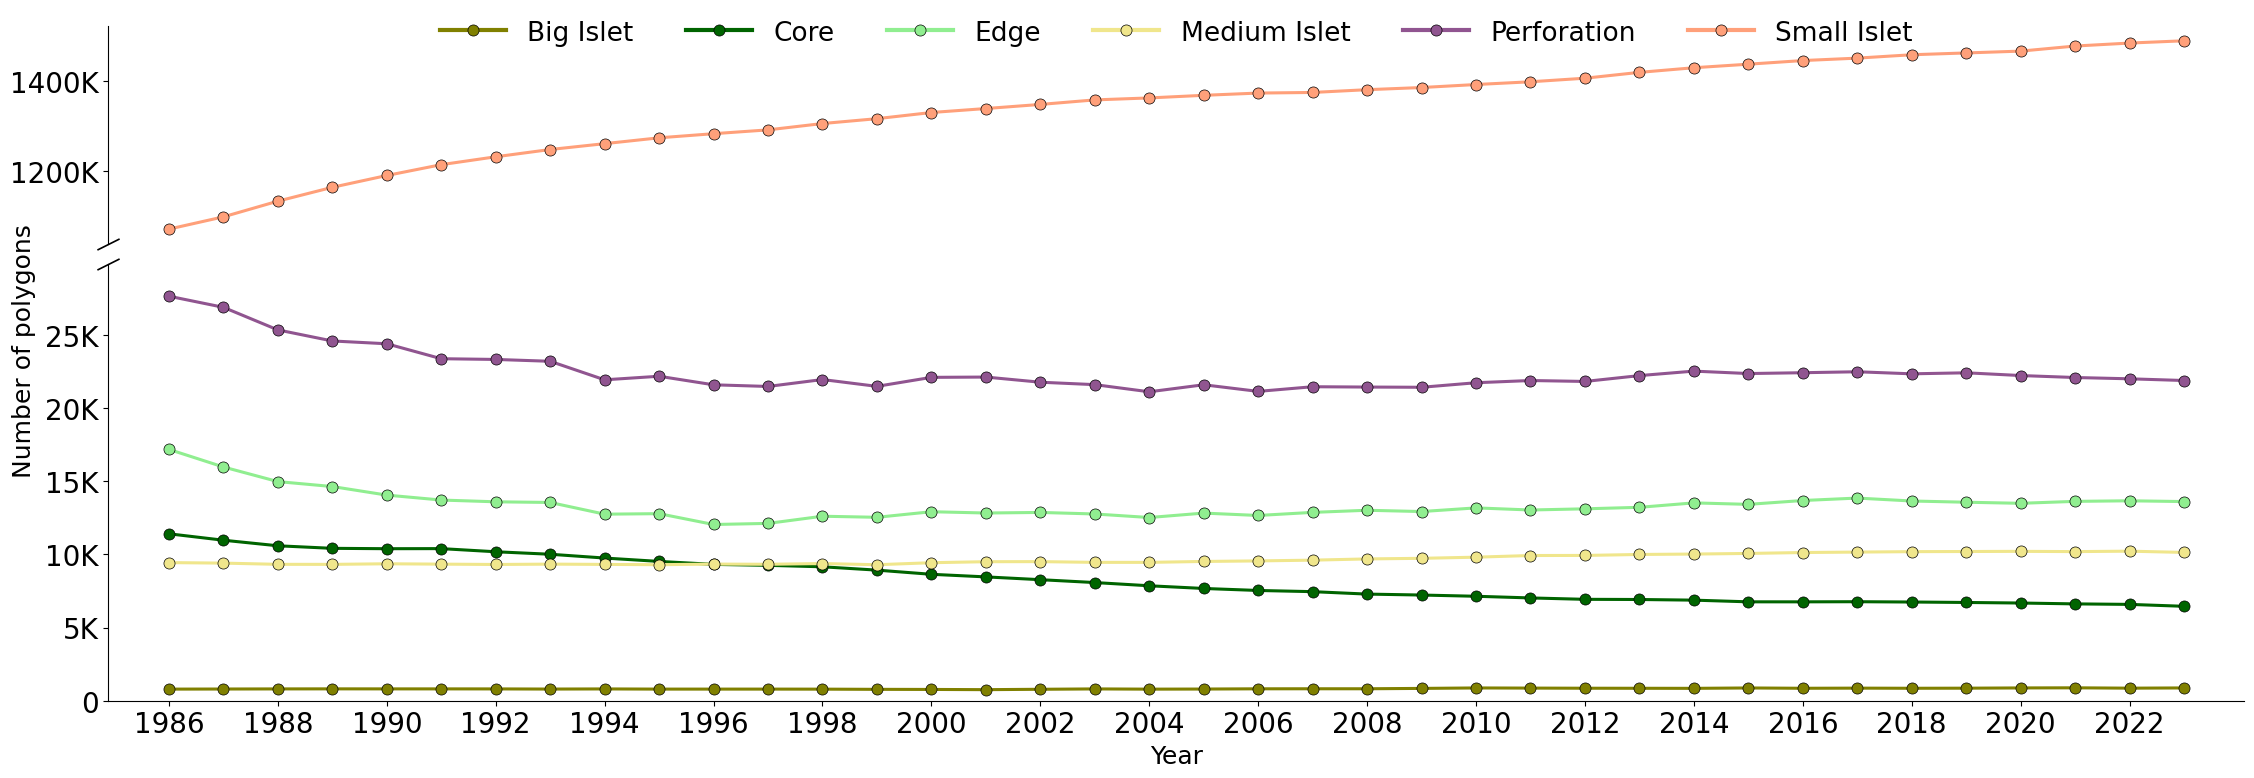

In [38]:
# folder assumed already defined earlier in the notebook
fragment_stats = pd.read_csv(folder / "mspa_polygon_area_stats_by_year_AOI.csv")
fragment_stats = fragment_stats[
    (~fragment_stats["year"].isin([1985, 2024]))
    & (fragment_stats["country"] == "APAF_studyarea")
]

# --- Categories and colors ---
target_categories = ['Big Islet', 'Core', 'Edge', 'Medium Islet', 'Perforation', 'Small Islet']
mspa_colors = {
    "Core": "#006400",
    "Small Islet": "#FFA07A",
    "Perforation": "#905590",
    "Edge": "#90EE90",
    "Medium Islet": "#F0E68C",
    "Big Islet": "#808000",
}

# --- n_polygons by year and class ---
frag_pivot = (
    fragment_stats[fragment_stats["class_name"].isin(target_categories)]
    .pivot_table(index="year", columns="class_name", values="n_polygons", aggfunc="sum")
    .sort_index()
)
plot_order = [c for c in target_categories if c in frag_pivot.columns]
years = frag_pivot.index.tolist()
x = np.arange(len(years))

# --- Y-axis break settings ---
# None = automatic. Or set manually, TOP panel first, e.g.:
# Y_RANGES = [(40000, 60000), (0, 8000)]
# Y_RANGES = [(40000, 60000), (8000, 15000), (0, 2500)]   # 3 panels also works
Y_RANGES = None
PAD = 0.08  # fractional padding above/below the data in each panel

def auto_ranges(pivot, pad=PAD, min_ratio=1.5):
    """Split classes into a 'high' and 'low' group at the largest gap in magnitude."""
    mins, maxs = pivot.min(), pivot.max()
    order = maxs.sort_values().index
    best_ratio, split = 0, None
    for i in range(len(order) - 1):
        lo_max = maxs[order[: i + 1]].max()
        hi_min = mins[order[i + 1 :]].min()
        if hi_min > lo_max:  # groups must not overlap
            ratio = hi_min / max(lo_max, 1)
            if ratio > best_ratio:
                best_ratio, split = ratio, i
    if split is None or best_ratio < min_ratio:
        return [(0, maxs.max() * (1 + pad))]  # no useful break
    lo_max = maxs[order[: split + 1]].max()
    hi_min = mins[order[split + 1 :]].min()
    hi_max = maxs.max()
    span = max(hi_max - hi_min, hi_max * 0.05)
    return [(hi_min - span * pad, hi_max + span * pad), (0, lo_max * (1 + pad))]

y_ranges = Y_RANGES if Y_RANGES is not None else auto_ranges(frag_pivot[plot_order])
print("Y ranges used (top -> bottom):", [(round(a), round(b)) for a, b in y_ranges])

# --- Font sizes ---
FS_AXIS_LABEL = 18   # was 18  ("Year", "Number of polygons")
FS_TICK = 20         # was 14  (year labels, y-axis numbers)
FS_TITLE = 14        # unchanged
FS_LEGEND = 19       # was 14  (class names)
FS_LEGEND_TITLE = 20 # was 15  (only used if you add a legend title)

def format_k(val, pos):
    if abs(val) >= 1000:
        return f"{val/1000:g}K"   # 1500 -> 1.5K, 12000 -> 12K
    return f"{val:.0f}"

# --- Figure: one panel per y-range, bottom (small values) panel gets more height ---
n = len(y_ranges)
height_ratios = [1] * (n - 1) + [2] if n > 1 else [1]
fig, axes = plt.subplots(
    n, 1, sharex=True, figsize=(24, 9),
    gridspec_kw={"height_ratios": height_ratios},
)
axes = np.atleast_1d(axes)

for ax, (lo, hi) in zip(axes, y_ranges):
    for cat in plot_order:
        ax.plot(
            x, frag_pivot[cat].to_numpy(), color=mspa_colors.get(cat),
            linestyle="-", marker="o", markersize=8,
            markeredgecolor="black", markeredgewidth=0.5, linewidth=2.2, zorder=3,
        )
    ax.set_ylim(lo, hi)
    ax.yaxis.set_major_formatter(FuncFormatter(format_k))
    ax.tick_params(axis="y", labelsize=FS_TICK)
    ax.spines["right"].set_visible(False)
    ax.margins(x=0.03)

axes[0].spines["top"].set_visible(False)

# --- Break styling between panels ---
d = 0.5
break_kw = dict(marker=[(-1, -d), (1, d)], markersize=16, linestyle="none",
                color="k", mec="k", mew=1.2, clip_on=False)
for upper, lower in zip(axes[:-1], axes[1:]):
    upper.spines["bottom"].set_visible(False)
    lower.spines["top"].set_visible(False)
    upper.tick_params(axis="x", which="both", bottom=False)
    upper.plot([0], [0], transform=upper.transAxes, **break_kw)
    lower.plot([0], [1], transform=lower.transAxes, **break_kw)

# --- Labels, ticks, title ---
step = 2
axes[-1].set_xticks(x[::step])
axes[-1].set_xticklabels([str(y) for y in years[::step]], rotation=0, fontsize=FS_TICK)
axes[-1].set_xlabel("Year", fontsize=FS_AXIS_LABEL)
fig.supylabel("Number of polygons", fontsize=FS_AXIS_LABEL, x=0.05)
#axes[0].set_title("Number of polygons by MSPA class and year — Study area", fontsize=FS_TITLE)

# --- Legend: horizontal, between title and plot ---
class_handles = [
    Line2D([0], [0], color=mspa_colors.get(cat), linewidth=3, marker="o",
           markersize=8, markeredgecolor="black", markeredgewidth=0.5, label=cat)
    for cat in plot_order
]
axes[0].legend(
    handles=class_handles, frameon=False,
    loc="lower center", bbox_to_anchor=(0.5, 0.8),
    ncol=len(plot_order), fontsize=FS_LEGEND,
    columnspacing=2.0, handlelength=2.5,
)

fig.subplots_adjust(left=0.09, right=0.98, top=0.86, hspace=0.06)
plt.show()

# Ecoregion

Y ranges used (top -> bottom): [(455638, 701427), (0, 14010)]


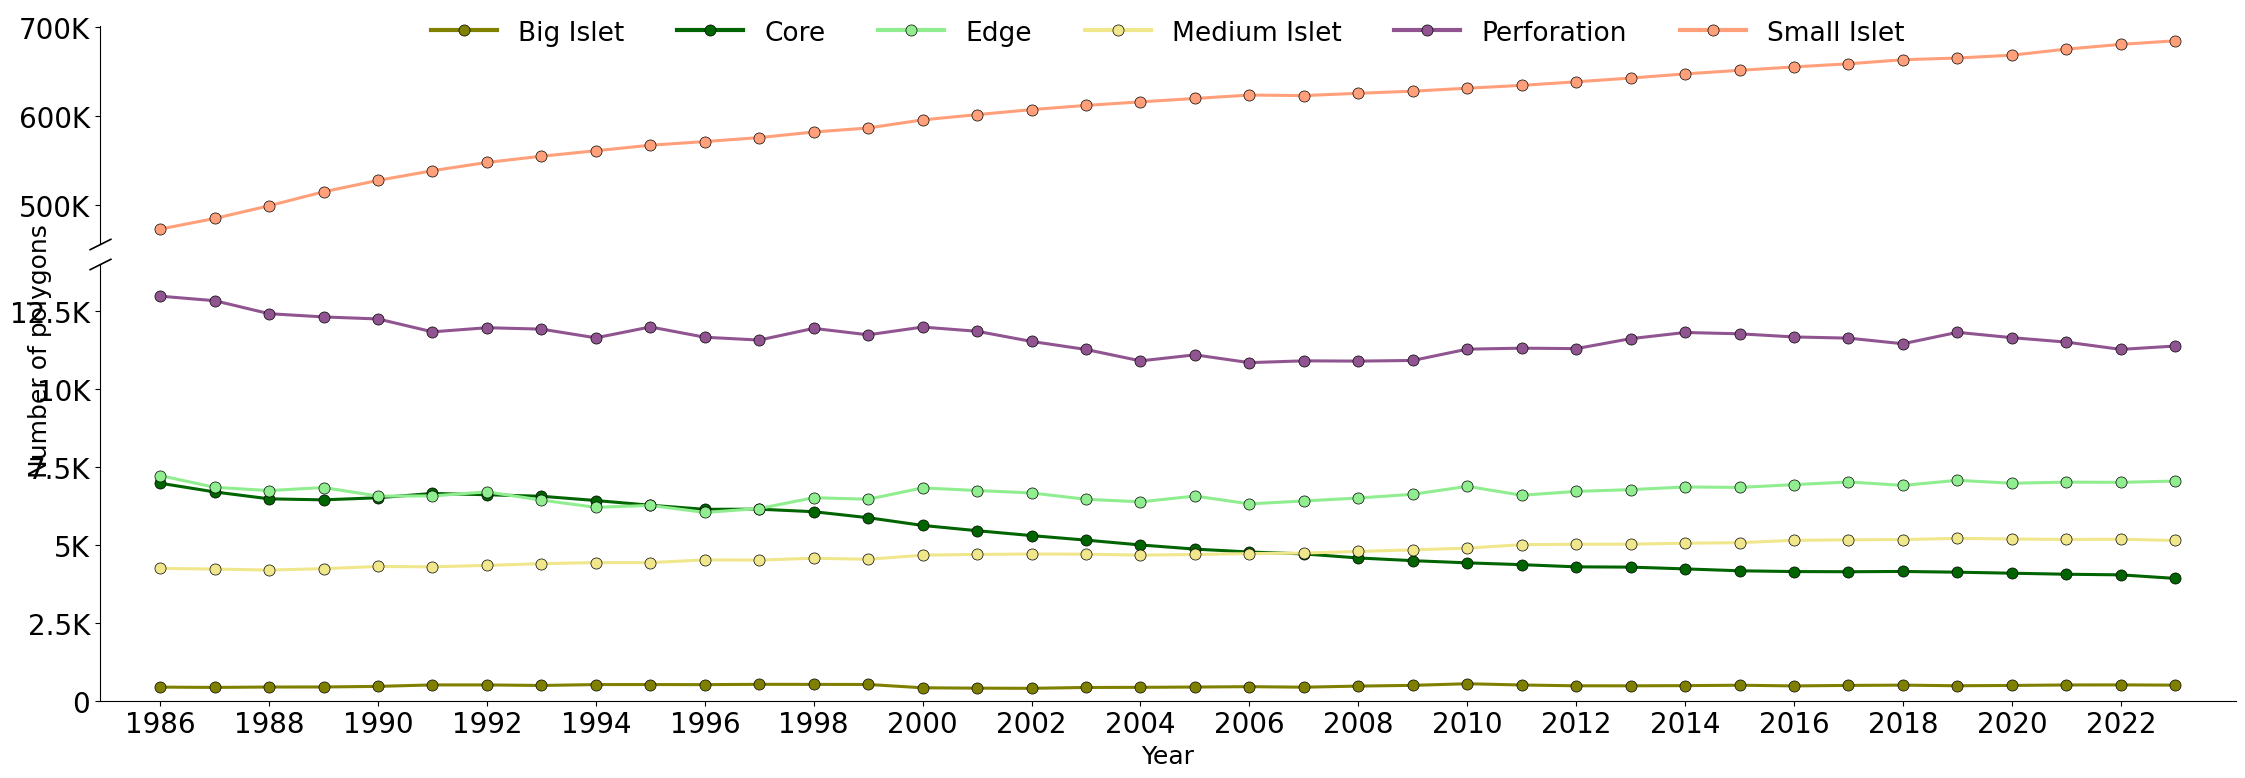

In [39]:
# folder assumed already defined earlier in the notebook
fragment_stats = pd.read_csv(folder / "mspa_polygon_area_stats_by_year_AOI.csv")
fragment_stats = fragment_stats[
    (~fragment_stats["year"].isin([1985, 2024]))
    & (fragment_stats["country"] == "APAF_ecoregion")
]

# --- Categories and colors ---
target_categories = ['Big Islet', 'Core', 'Edge', 'Medium Islet', 'Perforation', 'Small Islet']
mspa_colors = {
    "Core": "#006400",
    "Small Islet": "#FFA07A",
    "Perforation": "#905590",
    "Edge": "#90EE90",
    "Medium Islet": "#F0E68C",
    "Big Islet": "#808000",
}

# --- n_polygons by year and class ---
frag_pivot = (
    fragment_stats[fragment_stats["class_name"].isin(target_categories)]
    .pivot_table(index="year", columns="class_name", values="n_polygons", aggfunc="sum")
    .sort_index()
)
plot_order = [c for c in target_categories if c in frag_pivot.columns]
years = frag_pivot.index.tolist()
x = np.arange(len(years))

# --- Y-axis break settings ---
# None = automatic. Or set manually, TOP panel first, e.g.:
# Y_RANGES = [(40000, 60000), (0, 8000)]
# Y_RANGES = [(40000, 60000), (8000, 15000), (0, 2500)]   # 3 panels also works
Y_RANGES = None
PAD = 0.08  # fractional padding above/below the data in each panel

def auto_ranges(pivot, pad=PAD, min_ratio=1.5):
    """Split classes into a 'high' and 'low' group at the largest gap in magnitude."""
    mins, maxs = pivot.min(), pivot.max()
    order = maxs.sort_values().index
    best_ratio, split = 0, None
    for i in range(len(order) - 1):
        lo_max = maxs[order[: i + 1]].max()
        hi_min = mins[order[i + 1 :]].min()
        if hi_min > lo_max:  # groups must not overlap
            ratio = hi_min / max(lo_max, 1)
            if ratio > best_ratio:
                best_ratio, split = ratio, i
    if split is None or best_ratio < min_ratio:
        return [(0, maxs.max() * (1 + pad))]  # no useful break
    lo_max = maxs[order[: split + 1]].max()
    hi_min = mins[order[split + 1 :]].min()
    hi_max = maxs.max()
    span = max(hi_max - hi_min, hi_max * 0.05)
    return [(hi_min - span * pad, hi_max + span * pad), (0, lo_max * (1 + pad))]

y_ranges = Y_RANGES if Y_RANGES is not None else auto_ranges(frag_pivot[plot_order])
print("Y ranges used (top -> bottom):", [(round(a), round(b)) for a, b in y_ranges])

# --- Font sizes ---
FS_AXIS_LABEL = 18   # was 18  ("Year", "Number of polygons")
FS_TICK = 20         # was 14  (year labels, y-axis numbers)
FS_TITLE = 14        # unchanged
FS_LEGEND = 19       # was 14  (class names)
FS_LEGEND_TITLE = 20 # was 15  (only used if you add a legend title)

def format_k(val, pos):
    if abs(val) >= 1000:
        return f"{val/1000:g}K"   # 1500 -> 1.5K, 12000 -> 12K
    return f"{val:.0f}"

# --- Figure: one panel per y-range, bottom (small values) panel gets more height ---
n = len(y_ranges)
height_ratios = [1] * (n - 1) + [2] if n > 1 else [1]
fig, axes = plt.subplots(
    n, 1, sharex=True, figsize=(24, 9),
    gridspec_kw={"height_ratios": height_ratios},
)
axes = np.atleast_1d(axes)

for ax, (lo, hi) in zip(axes, y_ranges):
    for cat in plot_order:
        ax.plot(
            x, frag_pivot[cat].to_numpy(), color=mspa_colors.get(cat),
            linestyle="-", marker="o", markersize=8,
            markeredgecolor="black", markeredgewidth=0.5, linewidth=2.2, zorder=3,
        )
    ax.set_ylim(lo, hi)
    ax.yaxis.set_major_formatter(FuncFormatter(format_k))
    ax.tick_params(axis="y", labelsize=FS_TICK)
    ax.spines["right"].set_visible(False)
    ax.margins(x=0.03)

axes[0].spines["top"].set_visible(False)

# --- Break styling between panels ---
d = 0.5
break_kw = dict(marker=[(-1, -d), (1, d)], markersize=16, linestyle="none",
                color="k", mec="k", mew=1.2, clip_on=False)
for upper, lower in zip(axes[:-1], axes[1:]):
    upper.spines["bottom"].set_visible(False)
    lower.spines["top"].set_visible(False)
    upper.tick_params(axis="x", which="both", bottom=False)
    upper.plot([0], [0], transform=upper.transAxes, **break_kw)
    lower.plot([0], [1], transform=lower.transAxes, **break_kw)

# --- Labels, ticks, title ---
step = 2
axes[-1].set_xticks(x[::step])
axes[-1].set_xticklabels([str(y) for y in years[::step]], rotation=0, fontsize=FS_TICK)
axes[-1].set_xlabel("Year", fontsize=FS_AXIS_LABEL)
fig.supylabel("Number of polygons", fontsize=FS_AXIS_LABEL, x=0.06)
#axes[0].set_title("Number of polygons by MSPA class and year — APAF ecoregion", fontsize=FS_TITLE)

# --- Legend: horizontal, between title and plot ---
class_handles = [
    Line2D([0], [0], color=mspa_colors.get(cat), linewidth=3, marker="o",
           markersize=8, markeredgecolor="black", markeredgewidth=0.5, label=cat)
    for cat in plot_order
]
axes[0].legend(
    handles=class_handles, frameon=False,
    loc="lower center", bbox_to_anchor=(0.5, 0.8),
    ncol=len(plot_order), fontsize=FS_LEGEND,
    columnspacing=2.0, handlelength=2.5,
)

fig.subplots_adjust(left=0.09, right=0.98, top=0.86, hspace=0.06)
plt.show()

# Argentina

In [ ]:
# folder assumed already defined earlier in the notebook
fragment_stats = pd.read_csv(folder / "mspa_polygon_area_stats_by_year_AOI.csv")
fragment_stats = fragment_stats[
    (~fragment_stats["year"].isin([1985, 2024]))
    & (fragment_stats["country"] == "Argentina")
]

# --- Categories and colors ---
target_categories = ['Big Islet', 'Core', 'Edge', 'Medium Islet', 'Perforation', 'Small Islet']
mspa_colors = {
    "Core": "#006400",
    "Small Islet": "#FFA07A",
    "Perforation": "#905590",
    "Edge": "#90EE90",
    "Medium Islet": "#F0E68C",
    "Big Islet": "#808000",
}

# --- n_polygons by year and class ---
frag_pivot = (
    fragment_stats[fragment_stats["class_name"].isin(target_categories)]
    .pivot_table(index="year", columns="class_name", values="n_polygons", aggfunc="sum")
    .sort_index()
)
plot_order = [c for c in target_categories if c in frag_pivot.columns]
years = frag_pivot.index.tolist()
x = np.arange(len(years))

# --- Y-axis break settings ---
# None = automatic. Or set manually, TOP panel first, e.g.:
# Y_RANGES = [(40000, 60000), (8000, 15000)]
Y_RANGES = None
N_PANELS = 3               # panels found automatically (before dropping)
PAD = 0.08                 # fractional padding above/below the data in each panel
BOTTOM_FROM_ZERO = False   # True = bottom panel starts at 0
DROP_RANGES = [(5, 18)]    # panels to remove, as printed (rounded values)
HEIGHT_RATIOS = [1, 2]     # TOP first; ignored if length doesn't match panel count

def auto_ranges(pivot, n_panels=N_PANELS, pad=PAD, min_ratio=1.2):
    """Cut classes into groups at the (n_panels-1) largest non-overlapping gaps."""
    mins, maxs = pivot.min(), pivot.max()
    order = list(maxs.sort_values().index)
    cuts = []
    for i in range(1, len(order)):
        lo_max = maxs[order[:i]].max()
        hi_min = mins[order[i:]].min()
        if hi_min > lo_max:
            ratio = hi_min / max(lo_max, 1)
            if ratio >= min_ratio:
                cuts.append((ratio, i))
    chosen = sorted(i for _, i in sorted(cuts, reverse=True)[: n_panels - 1])
    if len(chosen) < n_panels - 1:
        print(f"Only {len(chosen)} valid break(s) found -> {len(chosen) + 1} panel(s).")
    groups = [order[a:b] for a, b in zip([0] + chosen, chosen + [len(order)])]
    ranges = []
    for g in groups:
        g_lo, g_hi = mins[g].min(), maxs[g].max()
        span = max(g_hi - g_lo, g_hi * 0.05)
        ranges.append((g_lo - span * pad, g_hi + span * pad))
    if BOTTOM_FROM_ZERO:
        ranges[0] = (0, ranges[0][1])
    print("Panel groups (top -> bottom):", groups[::-1])
    return ranges[::-1]   # top panel first

y_ranges = Y_RANGES if Y_RANGES is not None else auto_ranges(frag_pivot[plot_order])
print("Y ranges found (top -> bottom):", [(round(a), round(b)) for a, b in y_ranges])

# --- Drop unwanted panels ---
y_ranges = [(lo, hi) for lo, hi in y_ranges if (round(lo), round(hi)) not in DROP_RANGES]
print("Y ranges used  (top -> bottom):", [(round(a), round(b)) for a, b in y_ranges])

# Classes with at least one value inside a remaining panel (others are left out of the legend)
def is_visible(cat):
    v = frag_pivot[cat].dropna().to_numpy()
    return any(((v >= lo) & (v <= hi)).any() for lo, hi in y_ranges)

visible_classes = [c for c in plot_order if is_visible(c)]
hidden = [c for c in plot_order if c not in visible_classes]
if hidden:
    print("Not visible in any panel (removed from legend):", hidden)

# --- Font sizes ---
FS_AXIS_LABEL = 18
FS_TICK = 20
FS_TITLE = 14
FS_LEGEND = 19

def format_k(val, pos):
    if abs(val) >= 1000:
        return f"{val/1000:g}K"   # 1500 -> 1.5K, 12000 -> 12K
    return f"{val:.0f}"

# --- Figure ---
n = len(y_ranges)
height_ratios = HEIGHT_RATIOS if HEIGHT_RATIOS and len(HEIGHT_RATIOS) == n else [1] * n
fig, axes = plt.subplots(
    n, 1, sharex=True, figsize=(24, 11),
    gridspec_kw={"height_ratios": height_ratios},
)
axes = np.atleast_1d(axes)

for ax, (lo, hi) in zip(axes, y_ranges):
    for cat in visible_classes:
        ax.plot(
            x, frag_pivot[cat].to_numpy(), color=mspa_colors.get(cat),
            linestyle="-", marker="o", markersize=8,
            markeredgecolor="black", markeredgewidth=0.5, linewidth=2.2, zorder=3,
        )
    ax.set_ylim(lo, hi)
    ax.yaxis.set_major_formatter(FuncFormatter(format_k))
    ax.tick_params(axis="y", labelsize=FS_TICK)
    ax.spines["right"].set_visible(False)
    ax.margins(x=0.03)

axes[0].spines["top"].set_visible(False)

# --- Break marks between panels ---
d = 0.5
break_kw = dict(marker=[(-1, -d), (1, d)], markersize=16, linestyle="none",
                color="k", mec="k", mew=1.2, clip_on=False)
for upper, lower in zip(axes[:-1], axes[1:]):
    upper.spines["bottom"].set_visible(False)
    lower.spines["top"].set_visible(False)
    upper.tick_params(axis="x", which="both", bottom=False)
    upper.plot([0], [0], transform=upper.transAxes, **break_kw)
    lower.plot([0], [1], transform=lower.transAxes, **break_kw)

# --- Labels, ticks, title ---
step = 2
axes[-1].set_xticks(x[::step])
axes[-1].set_xticklabels([str(y) for y in years[::step]], rotation=0, fontsize=FS_TICK)
axes[-1].set_xlabel("Year", fontsize=FS_AXIS_LABEL)
fig.supylabel("Number of polygons", fontsize=FS_AXIS_LABEL, x=0.05)
# axes[0].set_title("Number of polygons by MSPA class and year — Argentina",
#                   fontsize=FS_TITLE, pad=45)

# --- Legend: horizontal, above the top panel ---
class_handles = [
    Line2D([0], [0], color=mspa_colors.get(cat), linewidth=3, marker="o",
           markersize=8, markeredgecolor="black", markeredgewidth=0.5, label=cat)
    for cat in visible_classes
]
axes[0].legend(
    handles=class_handles, frameon=False,
    loc="lower center", bbox_to_anchor=(0.5, 0.9),
    ncol=len(class_handles), fontsize=FS_LEGEND,
    columnspacing=2.0, handlelength=2.5,
)

fig.subplots_adjust(left=0.09, right=0.98, top=0.86, hspace=0.06)
plt.show()

In [3]:
# Laws - Slope
folder = Path(r"C:\Users\ahuvi\") # change to your folder

# folder assumed already defined earlier in the notebook
fragment_stats = pd.read_csv(folder / "mspa_polygon_area_stats_by_year_AOI.csv")
mspa_Argentina = pd.read_csv(folder / "histograms_mspa_long_Argentina_with_area_pct.csv")

target_categories = ['Big Islet', 'Core', 'Edge', 'Medium Islet', 'Perforation', 'Small Islet']
SLOPE_PERIODS = [(1986, 1992), (1992, 1997), (1997, 1999), (1999, 2010), (2010,2023)]

# --- MSPA area (million ha) by year and class ---
mspa_Argentina = mspa_Argentina.copy()
mspa_Argentina["year"] = mspa_Argentina["file"].str.extract(
    r"mspa_500mt_v500perforation_vIslets_Reclass_img_(\d{4})_v0806\.tif", expand=False
).astype(int)
area_pivot = (
    mspa_Argentina[mspa_Argentina["value_name"].isin(target_categories)]
    .pivot_table(index="year", columns="value_name", values="area_mha", aggfunc="mean")
)

# --- Number of polygons by year and class ---
frag_Argentina = fragment_stats[fragment_stats["country"] == "Argentina"]
poly_pivot = (
    frag_Argentina[frag_Argentina["class_name"].isin(target_categories)]
    .pivot_table(index="year", columns="class_name", values="n_polygons", aggfunc="sum")
)

def endpoint_slopes(pivot, periods):
    """(value at end year - value at start year) / number of years, per class and period."""
    out = {}
    for y1, y2 in periods:
        col = f"{y1}-{y2}"
        if y1 in pivot.index and y2 in pivot.index:
            out[col] = (pivot.loc[y2] - pivot.loc[y1]) / (y2 - y1)
        else:
            missing = [y for y in (y1, y2) if y not in pivot.index]
            print(f"Period {col}: year(s) {missing} not in data -> NaN")
            out[col] = pd.Series(np.nan, index=pivot.columns)
    return pd.DataFrame(out)

area_slopes = endpoint_slopes(area_pivot, SLOPE_PERIODS)
poly_slopes = endpoint_slopes(poly_pivot, SLOPE_PERIODS)

pd.set_option("display.width", 200)
print("\nArgentina — MSPA area slope (million ha per year):")
print(area_slopes.round(4))
print("\nArgentina — Number of polygons slope (polygons per year):")
print(poly_slopes.round(1))

area_slopes.to_csv(folder / "slopes_area_mha_per_year_Argentina.csv")
poly_slopes.to_csv(folder / "slopes_n_polygons_per_year_Argentina.csv")


Argentina — MSPA area slope (million ha per year):
              1986-1992  1992-1997  1997-1999  1999-2010  2010-2023
value_name                                                         
Big Islet       -0.0001     0.0004     0.0001     0.0001     0.0005
Core            -0.0408    -0.0101    -0.0136    -0.0136    -0.0015
Edge             0.0238     0.0009     0.0039     0.0041    -0.0011
Medium Islet    -0.0002     0.0007    -0.0018     0.0005    -0.0002
Perforation      0.0011    -0.0015    -0.0016    -0.0021    -0.0001
Small Islet      0.0007     0.0009     0.0015     0.0009     0.0004

Argentina — Number of polygons slope (polygons per year):
              1986-1992  1992-1997  1997-1999  1999-2010  2010-2023
class_name                                                         
Big Islet          -0.3        0.4        0.5        0.3        0.0
Core               30.5      -30.2       -9.5      -12.5       -7.9
Edge               -2.3        7.4       10.0       -6.5       13.9
Mediu

# Brazil

Y ranges used (top -> bottom): [(904476, 1282465), (0, 22389)]


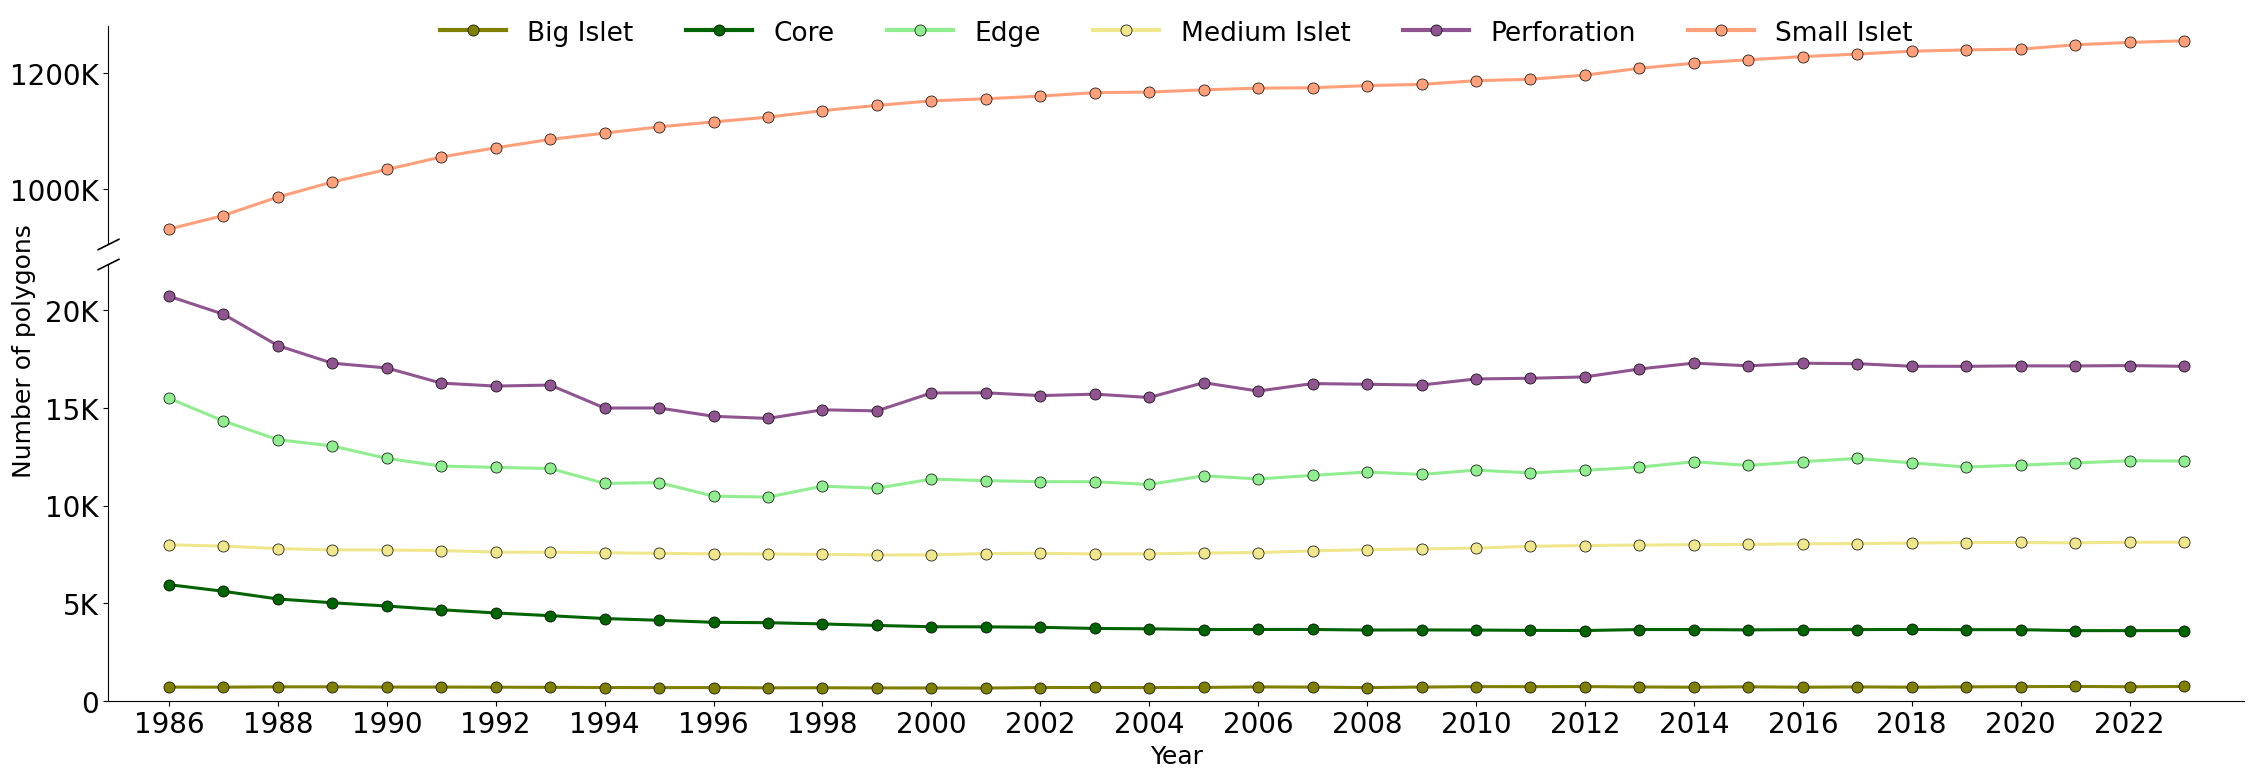

In [40]:
# folder assumed already defined earlier in the notebook
fragment_stats = pd.read_csv(folder / "mspa_polygon_area_stats_by_year_AOI.csv")
fragment_stats = fragment_stats[
    (~fragment_stats["year"].isin([1985, 2024]))
    & (fragment_stats["country"] == "Brazil")
]

# --- Categories and colors ---
target_categories = ['Big Islet', 'Core', 'Edge', 'Medium Islet', 'Perforation', 'Small Islet']
mspa_colors = {
    "Core": "#006400",
    "Small Islet": "#FFA07A",
    "Perforation": "#905590",
    "Edge": "#90EE90",
    "Medium Islet": "#F0E68C",
    "Big Islet": "#808000",
}

# --- n_polygons by year and class ---
frag_pivot = (
    fragment_stats[fragment_stats["class_name"].isin(target_categories)]
    .pivot_table(index="year", columns="class_name", values="n_polygons", aggfunc="sum")
    .sort_index()
)
plot_order = [c for c in target_categories if c in frag_pivot.columns]
years = frag_pivot.index.tolist()
x = np.arange(len(years))

# --- Y-axis break settings ---
# None = automatic. Or set manually, TOP panel first, e.g.:
# Y_RANGES = [(40000, 60000), (0, 8000)]
# Y_RANGES = [(40000, 60000), (8000, 15000), (0, 2500)]   # 3 panels also works
Y_RANGES = None
PAD = 0.08  # fractional padding above/below the data in each panel

def auto_ranges(pivot, pad=PAD, min_ratio=1.5):
    """Split classes into a 'high' and 'low' group at the largest gap in magnitude."""
    mins, maxs = pivot.min(), pivot.max()
    order = maxs.sort_values().index
    best_ratio, split = 0, None
    for i in range(len(order) - 1):
        lo_max = maxs[order[: i + 1]].max()
        hi_min = mins[order[i + 1 :]].min()
        if hi_min > lo_max:  # groups must not overlap
            ratio = hi_min / max(lo_max, 1)
            if ratio > best_ratio:
                best_ratio, split = ratio, i
    if split is None or best_ratio < min_ratio:
        return [(0, maxs.max() * (1 + pad))]  # no useful break
    lo_max = maxs[order[: split + 1]].max()
    hi_min = mins[order[split + 1 :]].min()
    hi_max = maxs.max()
    span = max(hi_max - hi_min, hi_max * 0.05)
    return [(hi_min - span * pad, hi_max + span * pad), (0, lo_max * (1 + pad))]

y_ranges = Y_RANGES if Y_RANGES is not None else auto_ranges(frag_pivot[plot_order])
print("Y ranges used (top -> bottom):", [(round(a), round(b)) for a, b in y_ranges])

# --- Font sizes ---
FS_AXIS_LABEL = 18   # was 18  ("Year", "Number of polygons")
FS_TICK = 20         # was 14  (year labels, y-axis numbers)
FS_TITLE = 14        # unchanged
FS_LEGEND = 19       # was 14  (class names)
FS_LEGEND_TITLE = 20 # was 15  (only used if you add a legend title)


def format_k(val, pos):
    if abs(val) >= 1000:
        return f"{val/1000:g}K"   # 1500 -> 1.5K, 12000 -> 12K
    return f"{val:.0f}"

# --- Figure: one panel per y-range, bottom (small values) panel gets more height ---
n = len(y_ranges)
height_ratios = [1] * (n - 1) + [2] if n > 1 else [1]
fig, axes = plt.subplots(
    n, 1, sharex=True, figsize=(24, 9),
    gridspec_kw={"height_ratios": height_ratios},
)
axes = np.atleast_1d(axes)

for ax, (lo, hi) in zip(axes, y_ranges):
    for cat in plot_order:
        ax.plot(
            x, frag_pivot[cat].to_numpy(), color=mspa_colors.get(cat),
            linestyle="-", marker="o", markersize=8,
            markeredgecolor="black", markeredgewidth=0.5, linewidth=2.2, zorder=3,
        )
    ax.set_ylim(lo, hi)
    ax.yaxis.set_major_formatter(FuncFormatter(format_k))
    ax.tick_params(axis="y", labelsize=FS_TICK)
    ax.spines["right"].set_visible(False)
    ax.margins(x=0.03)

axes[0].spines["top"].set_visible(False)

# --- Break styling between panels ---
d = 0.5
break_kw = dict(marker=[(-1, -d), (1, d)], markersize=16, linestyle="none",
                color="k", mec="k", mew=1.2, clip_on=False)
for upper, lower in zip(axes[:-1], axes[1:]):
    upper.spines["bottom"].set_visible(False)
    lower.spines["top"].set_visible(False)
    upper.tick_params(axis="x", which="both", bottom=False)
    upper.plot([0], [0], transform=upper.transAxes, **break_kw)
    lower.plot([0], [1], transform=lower.transAxes, **break_kw)

# --- Labels, ticks, title ---
step = 2
axes[-1].set_xticks(x[::step])
axes[-1].set_xticklabels([str(y) for y in years[::step]], rotation=0, fontsize=FS_TICK)
axes[-1].set_xlabel("Year", fontsize=FS_AXIS_LABEL)
fig.supylabel("Number of polygons", fontsize=FS_AXIS_LABEL, x=0.05)
#axes[0].set_title("Number of polygons by MSPA class and year — Brazil", fontsize=FS_TITLE)

# --- Legend: horizontal, between title and plot ---
class_handles = [
    Line2D([0], [0], color=mspa_colors.get(cat), linewidth=3, marker="o",
           markersize=8, markeredgecolor="black", markeredgewidth=0.5, label=cat)
    for cat in plot_order
]
axes[0].legend(
    handles=class_handles, frameon=False,
    loc="lower center", bbox_to_anchor=(0.5, 0.8),
    ncol=len(plot_order), fontsize=FS_LEGEND,
    columnspacing=2.0, handlelength=2.5,
)

fig.subplots_adjust(left=0.09, right=0.98, top=0.86, hspace=0.06)
plt.show()

In [4]:
# Laws - Slope
fragment_stats = pd.read_csv(folder / "mspa_polygon_area_stats_by_year_AOI.csv")
mspa_brazil = pd.read_csv(folder / "histograms_mspa_long_Brazil_with_area_pct.csv")

target_categories = ['Big Islet', 'Core', 'Edge', 'Medium Islet', 'Perforation', 'Small Islet']
SLOPE_PERIODS = [(1986, 2000), (2000, 2008), (2008, 2012), (2012, 2023)]

# --- MSPA area (million ha) by year and class ---
mspa_brazil = mspa_brazil.copy()
mspa_brazil["year"] = mspa_brazil["file"].str.extract(
    r"mspa_500mt_v500perforation_vIslets_Reclass_img_(\d{4})_v0806\.tif", expand=False
).astype(int)
area_pivot = (
    mspa_brazil[mspa_brazil["value_name"].isin(target_categories)]
    .pivot_table(index="year", columns="value_name", values="area_mha", aggfunc="mean")
)

# --- Number of polygons by year and class ---
frag_brazil = fragment_stats[fragment_stats["country"] == "Brazil"]
poly_pivot = (
    frag_brazil[frag_brazil["class_name"].isin(target_categories)]
    .pivot_table(index="year", columns="class_name", values="n_polygons", aggfunc="sum")
)

def endpoint_slopes(pivot, periods):
    """(value at end year - value at start year) / number of years, per class and period."""
    out = {}
    for y1, y2 in periods:
        col = f"{y1}-{y2}"
        if y1 in pivot.index and y2 in pivot.index:
            out[col] = (pivot.loc[y2] - pivot.loc[y1]) / (y2 - y1)
        else:
            missing = [y for y in (y1, y2) if y not in pivot.index]
            print(f"Period {col}: year(s) {missing} not in data -> NaN")
            out[col] = pd.Series(np.nan, index=pivot.columns)
    return pd.DataFrame(out)

area_slopes = endpoint_slopes(area_pivot, SLOPE_PERIODS)
poly_slopes = endpoint_slopes(poly_pivot, SLOPE_PERIODS)

pd.set_option("display.width", 200)
print("\nBrazil — MSPA area slope (million ha per year):")
print(area_slopes.round(4))
print("\nBrazil — Number of polygons slope (polygons per year):")
print(poly_slopes.round(1))

area_slopes.to_csv(folder / "slopes_area_mha_per_year_Brazil.csv")
poly_slopes.to_csv(folder / "slopes_n_polygons_per_year_Brazil.csv")


Brazil — MSPA area slope (million ha per year):
              1986-2000  2000-2008  2008-2012  2012-2023
value_name                                              
Big Islet       -0.0007     0.0070     0.0079     0.0002
Core            -0.0124     0.0006    -0.0000    -0.0005
Edge            -0.0763    -0.0010    -0.0061    -0.0054
Medium Islet    -0.0079     0.0056     0.0090     0.0045
Perforation     -0.0139    -0.0008     0.0008     0.0012
Small Islet      0.0013     0.0022     0.0106     0.0184

Brazil — Number of polygons slope (polygons per year):
              1986-2000  2000-2008  2008-2012  2012-2023
class_name                                              
Big Islet          -3.2        2.5       13.0        0.5
Core             -154.1      -21.1       -6.5       -0.4
Edge             -296.0       45.5       21.8       43.0
Medium Islet      -37.0       33.8       52.2       15.5
Perforation      -354.3       55.6       94.8       49.3
Small Islet     15848.5     3298.8     4

# Paraguay

Y ranges used (top -> bottom): [(123195, 218724), (0, 6490)]


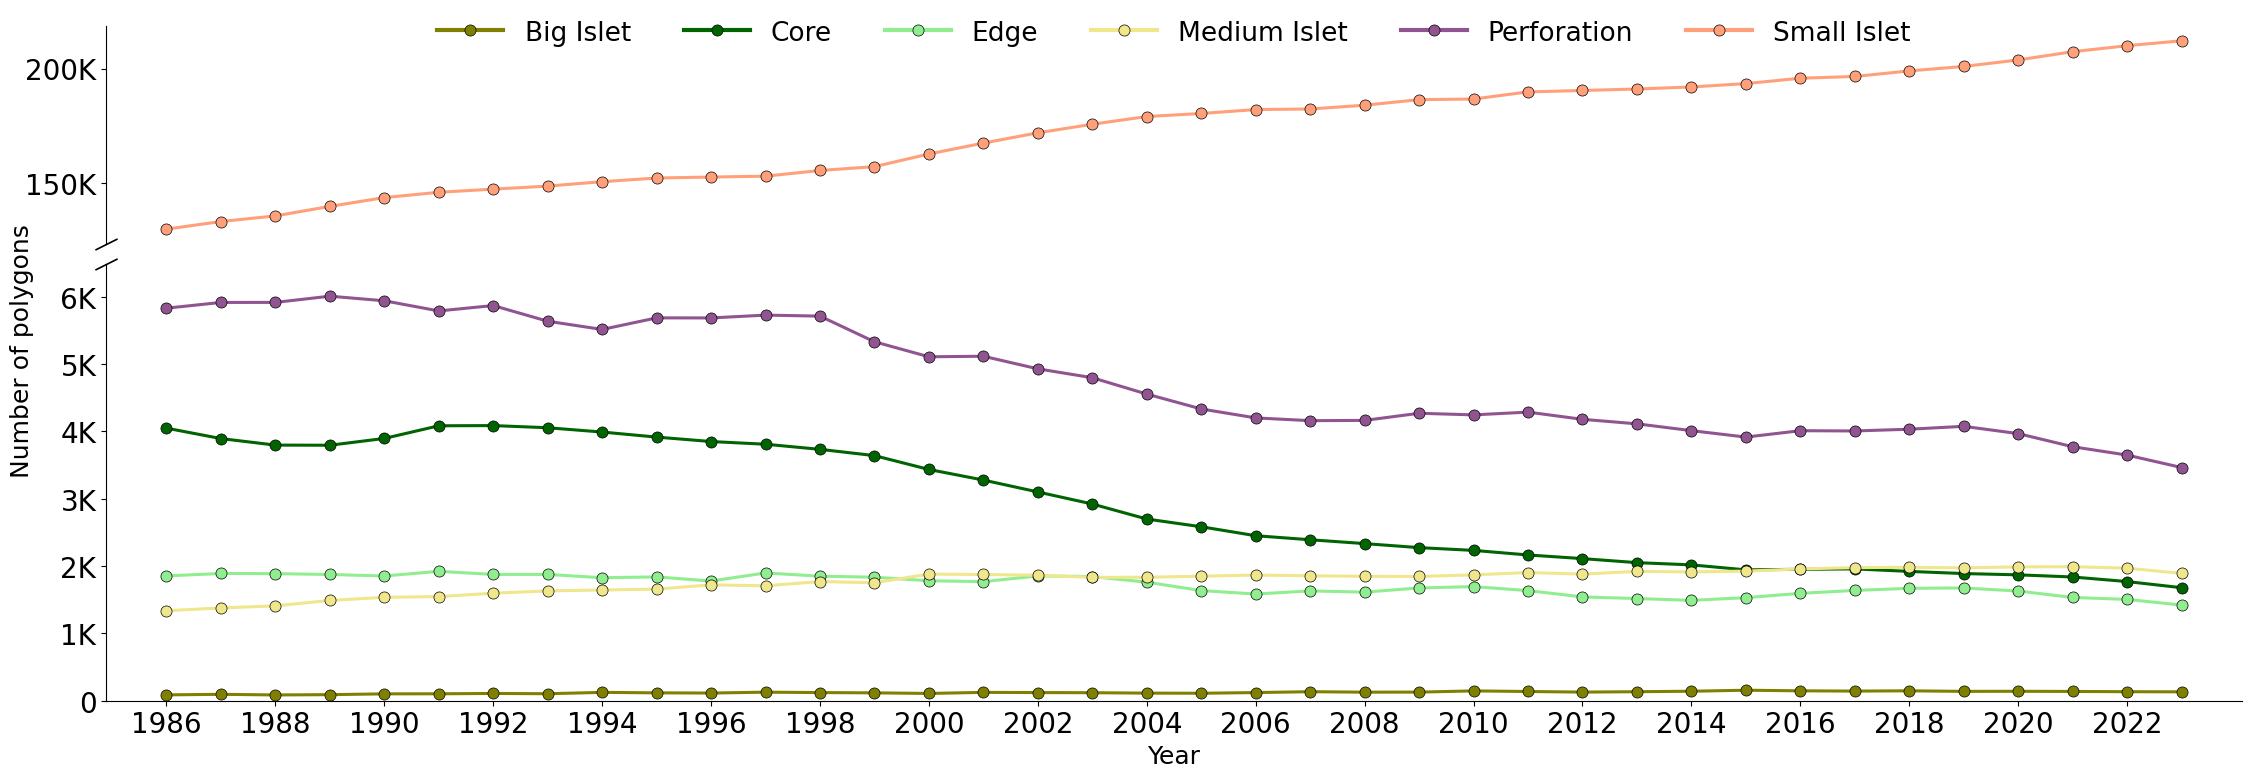

In [41]:
# folder assumed already defined earlier in the notebook
fragment_stats = pd.read_csv(folder / "mspa_polygon_area_stats_by_year_AOI.csv")
fragment_stats = fragment_stats[
    (~fragment_stats["year"].isin([1985, 2024]))
    & (fragment_stats["country"] == "Paraguay")
]

# --- Categories and colors ---
target_categories = ['Big Islet', 'Core', 'Edge', 'Medium Islet', 'Perforation', 'Small Islet']
mspa_colors = {
    "Core": "#006400",
    "Small Islet": "#FFA07A",
    "Perforation": "#905590",
    "Edge": "#90EE90",
    "Medium Islet": "#F0E68C",
    "Big Islet": "#808000",
}

# --- n_polygons by year and class ---
frag_pivot = (
    fragment_stats[fragment_stats["class_name"].isin(target_categories)]
    .pivot_table(index="year", columns="class_name", values="n_polygons", aggfunc="sum")
    .sort_index()
)
plot_order = [c for c in target_categories if c in frag_pivot.columns]
years = frag_pivot.index.tolist()
x = np.arange(len(years))

# --- Y-axis break settings ---
# None = automatic. Or set manually, TOP panel first, e.g.:
# Y_RANGES = [(40000, 60000), (0, 8000)]
# Y_RANGES = [(40000, 60000), (8000, 15000), (0, 2500)]   # 3 panels also works
Y_RANGES = None
PAD = 0.08  # fractional padding above/below the data in each panel

def auto_ranges(pivot, pad=PAD, min_ratio=1.5):
    """Split classes into a 'high' and 'low' group at the largest gap in magnitude."""
    mins, maxs = pivot.min(), pivot.max()
    order = maxs.sort_values().index
    best_ratio, split = 0, None
    for i in range(len(order) - 1):
        lo_max = maxs[order[: i + 1]].max()
        hi_min = mins[order[i + 1 :]].min()
        if hi_min > lo_max:  # groups must not overlap
            ratio = hi_min / max(lo_max, 1)
            if ratio > best_ratio:
                best_ratio, split = ratio, i
    if split is None or best_ratio < min_ratio:
        return [(0, maxs.max() * (1 + pad))]  # no useful break
    lo_max = maxs[order[: split + 1]].max()
    hi_min = mins[order[split + 1 :]].min()
    hi_max = maxs.max()
    span = max(hi_max - hi_min, hi_max * 0.05)
    return [(hi_min - span * pad, hi_max + span * pad), (0, lo_max * (1 + pad))]

y_ranges = Y_RANGES if Y_RANGES is not None else auto_ranges(frag_pivot[plot_order])
print("Y ranges used (top -> bottom):", [(round(a), round(b)) for a, b in y_ranges])

# --- Font sizes ---
FS_AXIS_LABEL = 18   # was 18  ("Year", "Number of polygons")
FS_TICK = 20         # was 14  (year labels, y-axis numbers)
FS_TITLE = 14        # unchanged
FS_LEGEND = 19       # was 14  (class names)
FS_LEGEND_TITLE = 20 # was 15  (only used if you add a legend title)

def format_k(val, pos):
    if abs(val) >= 1000:
        return f"{val/1000:g}K"   # 1500 -> 1.5K, 12000 -> 12K
    return f"{val:.0f}"

# --- Figure: one panel per y-range, bottom (small values) panel gets more height ---
n = len(y_ranges)
height_ratios = [1] * (n - 1) + [2] if n > 1 else [1]
fig, axes = plt.subplots(
    n, 1, sharex=True, figsize=(24, 9),
    gridspec_kw={"height_ratios": height_ratios},
)
axes = np.atleast_1d(axes)

for ax, (lo, hi) in zip(axes, y_ranges):
    for cat in plot_order:
        ax.plot(
            x, frag_pivot[cat].to_numpy(), color=mspa_colors.get(cat),
            linestyle="-", marker="o", markersize=8,
            markeredgecolor="black", markeredgewidth=0.5, linewidth=2.2, zorder=3,
        )
    ax.set_ylim(lo, hi)
    ax.yaxis.set_major_formatter(FuncFormatter(format_k))
    ax.tick_params(axis="y", labelsize=FS_TICK)
    ax.spines["right"].set_visible(False)
    ax.margins(x=0.03)

axes[0].spines["top"].set_visible(False)

# --- Break styling between panels ---
d = 0.5
break_kw = dict(marker=[(-1, -d), (1, d)], markersize=16, linestyle="none",
                color="k", mec="k", mew=1.2, clip_on=False)
for upper, lower in zip(axes[:-1], axes[1:]):
    upper.spines["bottom"].set_visible(False)
    lower.spines["top"].set_visible(False)
    upper.tick_params(axis="x", which="both", bottom=False)
    upper.plot([0], [0], transform=upper.transAxes, **break_kw)
    lower.plot([0], [1], transform=lower.transAxes, **break_kw)

# --- Labels, ticks, title ---
step = 2
axes[-1].set_xticks(x[::step])
axes[-1].set_xticklabels([str(y) for y in years[::step]], rotation=0, fontsize=FS_TICK)
axes[-1].set_xlabel("Year", fontsize=FS_AXIS_LABEL)
fig.supylabel("Number of polygons", fontsize=FS_AXIS_LABEL, x=0.05)
#axes[0].set_title("Number of polygons by MSPA class and year — Paraguay", fontsize=FS_TITLE)

# --- Legend: horizontal, between title and plot ---
class_handles = [
    Line2D([0], [0], color=mspa_colors.get(cat), linewidth=3, marker="o",
           markersize=8, markeredgecolor="black", markeredgewidth=0.5, label=cat)
    for cat in plot_order
]
axes[0].legend(
    handles=class_handles, frameon=False,
    loc="lower center", bbox_to_anchor=(0.5, 0.8),
    ncol=len(plot_order), fontsize=FS_LEGEND,
    columnspacing=2.0, handlelength=2.5,
)

fig.subplots_adjust(left=0.09, right=0.98, top=0.86, hspace=0.06)
plt.show()

In [5]:
# Laws - Slope
fragment_stats = pd.read_csv(folder / "mspa_polygon_area_stats_by_year_AOI.csv")
mspa_Paraguay = pd.read_csv(folder / "histograms_mspa_long_Paraguay_with_area_pct.csv")

target_categories = ['Big Islet', 'Core', 'Edge', 'Medium Islet', 'Perforation', 'Small Islet']
SLOPE_PERIODS = [(1986, 2004), (2004, 2006), (2006, 2008), (2008, 2013), (2013, 2018), (2018, 2020), (2020, 2023)]

# --- MSPA area (million ha) by year and class ---
mspa_Paraguay = mspa_Paraguay.copy()
mspa_Paraguay["year"] = mspa_Paraguay["file"].str.extract(
    r"mspa_500mt_v500perforation_vIslets_Reclass_img_(\d{4})_v0806\.tif", expand=False
).astype(int)
area_pivot = (
    mspa_Paraguay[mspa_Paraguay["value_name"].isin(target_categories)]
    .pivot_table(index="year", columns="value_name", values="area_mha", aggfunc="mean")
)

# --- Number of polygons by year and class ---
frag_Paraguay = fragment_stats[fragment_stats["country"] == "Paraguay"]
poly_pivot = (
    frag_Paraguay[frag_Paraguay["class_name"].isin(target_categories)]
    .pivot_table(index="year", columns="class_name", values="n_polygons", aggfunc="sum")
)

def endpoint_slopes(pivot, periods):
    """(value at end year - value at start year) / number of years, per class and period."""
    out = {}
    for y1, y2 in periods:
        col = f"{y1}-{y2}"
        if y1 in pivot.index and y2 in pivot.index:
            out[col] = (pivot.loc[y2] - pivot.loc[y1]) / (y2 - y1)
        else:
            missing = [y for y in (y1, y2) if y not in pivot.index]
            print(f"Period {col}: year(s) {missing} not in data -> NaN")
            out[col] = pd.Series(np.nan, index=pivot.columns)
    return pd.DataFrame(out)

area_slopes = endpoint_slopes(area_pivot, SLOPE_PERIODS)
poly_slopes = endpoint_slopes(poly_pivot, SLOPE_PERIODS)

pd.set_option("display.width", 200)
print("\nParaguay — MSPA area slope (million ha per year):")
print(area_slopes.round(4))
print("\nParaguay — Number of polygons slope (polygons per year):")
print(poly_slopes.round(1))

area_slopes.to_csv(folder / "slopes_area_mha_per_year_Paraguay.csv")
poly_slopes.to_csv(folder / "slopes_n_polygons_per_year_Paraguay.csv")


Paraguay — MSPA area slope (million ha per year):
              1986-2004  2004-2006  2006-2008  2008-2013  2013-2018  2018-2020  2020-2023
value_name                                                                               
Big Islet        0.0011     0.0026     0.0063     0.0004     0.0015    -0.0042    -0.0020
Core            -0.0826    -0.0268    -0.0130    -0.0148    -0.0081    -0.0133    -0.0195
Edge            -0.0620    -0.0486    -0.0263    -0.0299    -0.0091    -0.0072    -0.0453
Medium Islet     0.0050     0.0025    -0.0001     0.0027     0.0020     0.0040    -0.0063
Perforation     -0.0073    -0.0104     0.0024    -0.0039    -0.0035    -0.0026    -0.0070
Small Islet      0.0130     0.0078     0.0143     0.0083     0.0052    -0.0004    -0.0030

Paraguay — Number of polygons slope (polygons per year):
              1986-2004  2004-2006  2006-2008  2008-2013  2013-2018  2018-2020  2020-2023
class_name                                                                       